# 05 Probabilidad de ganar según el plazo

**Proyecto:** Análisis de estrategias de inversión en el S&P 500

En los notebooks anteriores he calculado cuánto se ha ganado. En este me hago una pregunta distinta: **cuántas veces se ha ganado**.

La rentabilidad media esconde algo importante, y es que no todo el mundo entra el mismo día. Quien invirtió en enero de 2020 vio caer su dinero un 34 % dos meses después. Quien invirtió en abril de 2020 ganó desde el primer mes. La media de los dos no cuenta lo que vivió ninguno.

Para medirlo pruebo todas las fechas de entrada posibles y, para cada plazo (1, 3, 5, 10 y 20 años), cuento en qué porcentaje de los casos se acabó con ganancias.

### Qué voy a hacer

Cargo el histórico completo del índice desde 1993.

Me quedo con un precio por mes.

Calculo la rentabilidad de todas las ventanas posibles de cada plazo.

Cuento cuántas acabaron en positivo y guardo los resultados para Power BI.

## 1. Cargar los datos

Para este notebook uso `indice_largo.csv`, que tiene los precios del ETF SPY desde 1993.

En el resto del proyecto trabajo con el periodo 2016-2026, porque es el que tengo disponible para todas las empresas. Pero aquí solo necesito el índice, y para estudiar plazos de diez o veinte años hacen falta muchos más años de histórico.

El notebook detecta automáticamente si se está ejecutando en Google Colab o en local, de forma que cualquier persona pueda ejecutarlo sin modificar las rutas.

In [1]:
# Importo pandas para trabajar con tablas
import pandas as pd
# Importo os para poder crear carpetas si no existen
import os

# Compruebo dónde se está ejecutando el notebook
try:
    # Si estoy en Colab, conecto mi Drive y uso mi carpeta
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_PROYECTO = "/content/drive/MyDrive/PORTFOLIO MARCOS GUERRERO SANCHEZ/analisis-estrategias-inversion/"
except ImportError:
    # Si no estoy en Colab, uso la carpeta donde esté el proyecto descargado
    # El ../ sube un nivel, porque el notebook está dentro de Notebooks/
    RUTA_PROYECTO = "../"

# Carpeta con los datos originales y carpeta donde guardo los resultados
RUTA = RUTA_PROYECTO + "Data/Raw/"
RUTA_PROCESSED = RUTA_PROYECTO + "Data/Processed/"

# Si la carpeta de resultados no existe, la creo
os.makedirs(RUTA_PROCESSED, exist_ok=True)

# Cargo el histórico largo del índice
# Lo leo de Raw y no de Processed porque la limpieza del notebook 02 servía para
# detectar empresas con precios de relleno, y aquí solo hay un ETF con cotización real
indice = pd.read_csv(RUTA + "indice_largo.csv", parse_dates=["Date"])

# Me aseguro de que está ordenado por fecha
indice = indice.sort_values("Date")

print("Tamaño del índice:", indice.shape)
print("Desde:", indice["Date"].min().date(), "hasta:", indice["Date"].max().date())
print("Años de datos:", round((indice["Date"].max() - indice["Date"].min()).days / 365.25, 1))

Mounted at /content/drive
Tamaño del índice: (8482, 6)
Desde: 1993-01-29 hasta: 2026-10-09
Años de datos: 33.7


## 2. Un precio por mes

El índice tiene más de 8.000 días. Si probara todas las fechas de entrada día a día saldrían demasiadas combinaciones y los resultados serían casi idénticos, porque dos días seguidos apenas se diferencian.

Por eso me quedo con el último precio de cada mes. Así tengo unas 400 fechas de entrada posibles, que es suficiente y mucho más manejable.

In [2]:
# Creo una columna con el mes de cada fecha
# to_period("M") convierte una fecha como 1993-03-15 en el periodo 1993-03
indice["mes"] = indice["Date"].dt.to_period("M")

# Me quedo con el último precio de cada mes
# groupby("mes") agrupa los días por mes y last() coge el último de cada grupo
# Funciona porque antes he ordenado la tabla por fecha
precios_mes = indice.groupby("mes")["Close"].last()

print("Meses disponibles:", len(precios_mes))
print()
print(precios_mes.head())

Meses disponibles: 406

mes
1993-01    24.053537
1993-02    24.310143
1993-03    24.854671
1993-04    24.218691
1993-05    24.871876
Freq: M, Name: Close, dtype: float64


## 3. Calculo todas las ventanas posibles

Una ventana es un periodo de inversión completo: una fecha de entrada y una de salida.

Por ejemplo, para el plazo de 10 años una ventana sería entrar en enero de 1996 y salir en enero de 2006. La siguiente sería febrero de 1996 a febrero de 2006, y así hasta donde lleguen los datos.

Para cada ventana calculo cuánto se ganó o se perdió.

In [3]:
# Los plazos que quiero probar, en años
plazos = [1, 3, 5, 10, 20]

# Creo una lista vacía donde iré guardando el resultado de cada ventana
filas = []

# Recorro cada plazo
for anios in plazos:

    # Paso los años a meses, porque mi tabla va por meses
    meses = anios * 12

    # Recorro todas las fechas de entrada posibles
    # Paro en len(precios_mes) - meses para no salirme de la tabla al buscar la fecha de salida
    for i in range(len(precios_mes) - meses):

        # Precio del mes de entrada
        precio_inicio = precios_mes.iloc[i]
        # Precio del mes de salida, que está "meses" posiciones más adelante
        precio_final = precios_mes.iloc[i + meses]

        # Calculo cuánto se ganó o se perdió en esa ventana
        rentabilidad = (precio_final - precio_inicio) / precio_inicio

        # Guardo el resultado de esta ventana
        # Uso str() en las fechas porque son periodos de pandas y no se guardan bien en un CSV
        filas.append({
            "plazo_anios": anios,
            "mes_inicio": str(precios_mes.index[i]),
            "mes_fin": str(precios_mes.index[i + meses]),
            "rentabilidad": rentabilidad
        })

# Convierto la lista en una tabla
ventanas = pd.DataFrame(filas)

print("Ventanas calculadas:", len(ventanas))
print()
# Compruebo cuántas ventanas han salido de cada plazo
print(ventanas["plazo_anios"].value_counts().sort_index())

Ventanas calculadas: 1562

plazo_anios
1     394
3     370
5     346
10    286
20    166
Name: count, dtype: int64


## 4. ¿Cuántas veces se gana?

Ahora agrupo las ventanas por plazo y cuento en cuántas se acabó con ganancias.

In [4]:
# Marco con True las ventanas en las que se acabó ganando dinero
ventanas["gana"] = ventanas["rentabilidad"] > 0

# Agrupo por plazo y calculo el resumen de cada uno
# sum() sobre una columna de True y False cuenta los True, porque True vale 1
resumen = ventanas.groupby("plazo_anios").agg(
    ventanas=("rentabilidad", "count"),
    veces_que_gana=("gana", "sum"),
    rentabilidad_mediana=("rentabilidad", "median"),
    peor_resultado=("rentabilidad", "min"),
    mejor_resultado=("rentabilidad", "max")
).reset_index()

# Calculo el porcentaje de veces que se gana
resumen["porcentaje_gana"] = resumen["veces_que_gana"] / resumen["ventanas"]

# Calculo también la rentabilidad anual equivalente de la ventana mediana
# Es la misma fórmula que usé en el notebook 03
resumen["rentabilidad_anual_mediana"] = (1 + resumen["rentabilidad_mediana"]) ** (1 / resumen["plazo_anios"]) - 1

resumen

,plazo_anios,ventanas,veces_que_gana,rentabilidad_mediana,peor_resultado,mejor_resultado,porcentaje_gana,rentabilidad_anual_mediana
0,1,394,324,0.146013,-0.434244,0.562311,0.822335,0.146013
1,3,370,310,0.406900,-0.413252,1.318704,0.837838,0.120524
2,5,346,297,0.721003,-0.291881,2.497052,0.858382,0.114696
3,10,286,262,1.326039,-0.296022,3.623049,0.916084,0.088082
4,20,166,166,4.405983,1.501698,7.583511,1.000000,0.088037


In [5]:
# Muestro el resumen en porcentaje para que se lea mejor
# Hago una copia para no modificar la tabla original
vista = resumen.copy()
columnas = ["porcentaje_gana", "rentabilidad_mediana", "peor_resultado",
            "mejor_resultado", "rentabilidad_anual_mediana"]
vista[columnas] = (vista[columnas] * 100).round(1)
vista

,plazo_anios,ventanas,veces_que_gana,rentabilidad_mediana,peor_resultado,mejor_resultado,porcentaje_gana,rentabilidad_anual_mediana
0,1,394,324,14.6,-43.4,56.2,82.2,14.6
1,3,370,310,40.7,-41.3,131.9,83.8,12.1
2,5,346,297,72.1,-29.2,249.7,85.8,11.5
3,10,286,262,132.6,-29.6,362.3,91.6,8.8
4,20,166,166,440.6,150.2,758.4,100.0,8.8


La tabla se lee de arriba abajo: cuantos más años, más veces se gana.

A un año se ganó en el 82,2 % de los casos, pero el peor resultado fue un −43,4 %. A cinco años el porcentaje sube al 85,8 % y la peor pérdida se queda en −29,2 %.

El salto grande está en los plazos largos. A diez años se ganó en el 91,6 % de los periodos, y a veinte años se ganó en los 166 periodos analizados, el 100 %. Además, el peor de esos 166 periodos acabó con un +150,2 %: a quien peor le fue multiplicó su dinero por dos y medio.

Me llamó la atención que la rentabilidad anual mediana baje según aumenta el plazo, del 14,6 % al 8,8 %. Tiene explicación: los periodos de un año caben en cualquier momento de los 33 años, incluidos los últimos, que han sido muy buenos. Los de veinte años empiezan como mucho en 2006, así que todos incluyen por fuerza la década de 2000, que fue mala. No es que invertir más tiempo dé menos al año, es que son periodos distintos.

## 5. ¿Cuándo se perdió dinero?

Me interesa ver no solo cuántas veces se perdió, sino **cuándo**. Si las pérdidas se concentran en unas fechas de entrada concretas, eso dice mucho más que un porcentaje suelto.

In [6]:
# Me quedo con las ventanas que acabaron en pérdidas
perdidas = ventanas[ventanas["gana"] == False]

# Para cada plazo, miro entre qué fechas de entrada se perdió dinero
for anios in plazos:

    # Filtro las pérdidas de ese plazo
    perdidas_plazo = perdidas[perdidas["plazo_anios"] == anios]

    print("Plazo de", anios, "años:", len(perdidas_plazo), "ventanas en pérdidas")

    # Si hubo alguna, muestro entre qué meses de entrada se produjeron
    # Compruebo antes de calcular porque min() sobre una tabla vacía daría error
    if len(perdidas_plazo) > 0:
        print("   Entradas entre", perdidas_plazo["mes_inicio"].min(),
              "y", perdidas_plazo["mes_inicio"].max())
        print("   Peor resultado:", round(perdidas_plazo["rentabilidad"].min() * 100, 1), "%")
    print()

Plazo de 1 años: 70 ventanas en pérdidas
   Entradas entre 1999-11 y 2022-03
   Peor resultado: -43.4 %

Plazo de 3 años: 60 ventanas en pérdidas
   Entradas entre 1998-10 y 2007-12
   Peor resultado: -41.3 %

Plazo de 5 años: 49 ventanas en pérdidas
   Entradas entre 1997-09 y 2007-05
   Peor resultado: -29.2 %

Plazo de 10 años: 24 ventanas en pérdidas
   Entradas entre 1998-11 y 2000-10
   Peor resultado: -29.6 %

Plazo de 20 años: 0 ventanas en pérdidas



Las pérdidas no se reparten al azar por el calendario, sino que se concentran en fechas muy concretas.

A un año se podía perder entrando en casi cualquier momento, desde 1999 hasta 2022. A tres y cinco años las entradas con pérdidas se limitan a los años previos a la burbuja puntocom y a los meses anteriores a la crisis de 2008.

A diez años el caso es llamativo: las 24 ventanas que acabaron en pérdidas empiezan todas entre noviembre de 1998 y octubre de 2000. Son 24 meses de los 286 posibles. Para perder dinero en un plazo de diez años había que haber entrado justo en los dos años de la burbuja tecnológica.

A veinte años no hubo ninguna pérdida en todo el periodo analizado.

## 6. Guardo los resultados

Guardo las dos tablas en Data/Processed, para usarlas después en Power BI.

In [7]:
# Guardo las dos tablas
# index=False evita que se añada una columna extra con la numeración de las filas
ventanas.to_csv(RUTA_PROCESSED + "ventanas_plazo.csv", index=False)
resumen.to_csv(RUTA_PROCESSED + "resumen_plazo.csv", index=False)

print("Ventanas:", ventanas.shape)
print("Resumen:", resumen.shape)

Ventanas: (1562, 5)
Resumen: (5, 8)


In [8]:
# Calculo la evolución de una inversión única según el plazo elegido
# Para cada plazo cojo el tramo final del histórico y divido cada precio entre el del primer día

# La fecha más reciente que tengo
fecha_fin = indice["Date"].max()

# Lista vacía donde iré guardando los resultados
filas_evolucion = []

# Recorro cada plazo
for anios in plazos:

    # Calculo la fecha de inicio restando los años a la fecha final
    # DateOffset entiende de años y meses, al contrario que una resta de días normal
    fecha_inicio = fecha_fin - pd.DateOffset(years=anios)

    # Me quedo con los días desde esa fecha hasta hoy
    tramo = indice[indice["Date"] >= fecha_inicio]

    # Precio del primer día del tramo
    precio_inicio = tramo["Close"].iloc[0]

    # Para cada día calculo por cuánto se ha multiplicado la inversión
    for fecha, precio in zip(tramo["Date"], tramo["Close"]):
        filas_evolucion.append({
            "plazo_anios": anios,
            "Date": fecha,
            "multiplo": precio / precio_inicio
        })

# Convierto la lista en tabla y la guardo
evolucion_plazos = pd.DataFrame(filas_evolucion)
evolucion_plazos.to_csv(RUTA_PROCESSED + "evolucion_plazos.csv", index=False)

print("Filas:", len(evolucion_plazos))
print(evolucion_plazos.groupby("plazo_anios")["Date"].agg(["min", "max", "count"]))

Filas: 9807
                   min        max  count
plazo_anios                             
1           2025-10-09 2026-10-09    252
3           2023-10-09 2026-10-09    754
5           2021-10-11 2026-10-09   1255
10          2016-10-10 2026-10-09   2514
20          2006-10-09 2026-10-09   5032


## 7. Gráficos

Hago dos gráficos sencillos para ver los resultados. Los del dashboard los haré después en Power BI.

In [9]:
# Importo la librería para hacer gráficos
import matplotlib.pyplot as plt

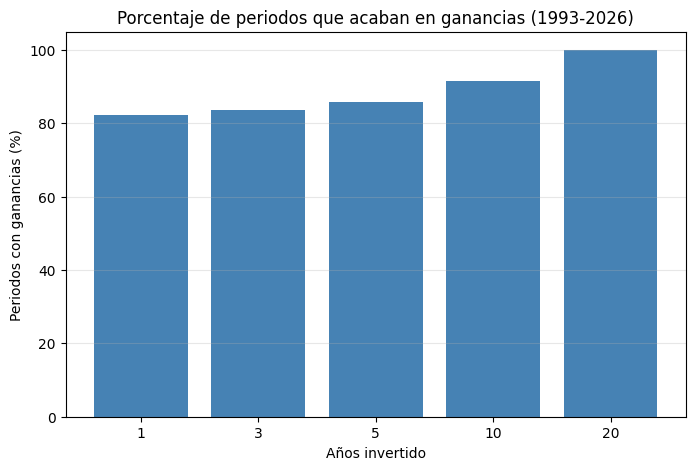

In [10]:
# Creo el gráfico y le doy un tamaño (ancho, alto) en pulgadas
plt.figure(figsize=(8, 5))

# Dibujo una barra por plazo con el porcentaje de veces que se gana
# astype(str) convierte el plazo en texto para que las barras salgan equiespaciadas
# Si lo dejara como número, matplotlib dejaría un hueco enorme entre el 10 y el 20
plt.bar(resumen["plazo_anios"].astype(str), resumen["porcentaje_gana"] * 100,
        color="steelblue")

plt.title("Porcentaje de periodos que acaban en ganancias (1993-2026)")
plt.xlabel("Años invertido")
plt.ylabel("Periodos con ganancias (%)")

# Fijo el eje de 0 a 105 para que se vea cuánto falta hasta el 100 %
plt.ylim(0, 105)
plt.grid(alpha=0.3, axis="y")
plt.show()

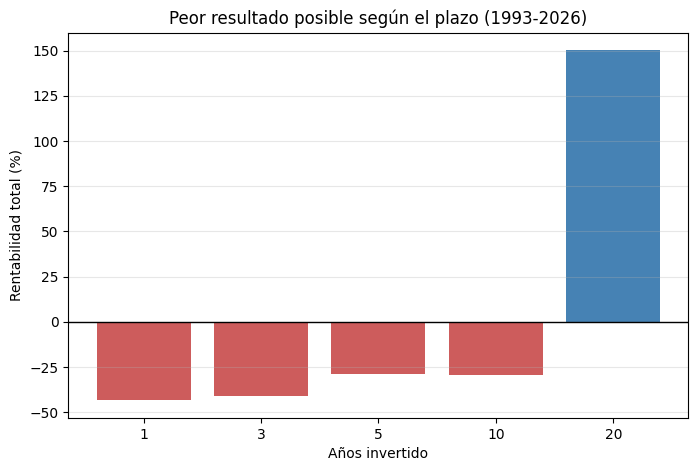

In [11]:
plt.figure(figsize=(8, 5))

# Elijo el color de cada barra según si el peor resultado fue pérdida o ganancia
colores = []
for valor in resumen["peor_resultado"]:
    if valor < 0:
        colores.append("indianred")
    else:
        colores.append("steelblue")

# Dibujo una barra por plazo con el peor resultado de todos sus periodos
plt.bar(resumen["plazo_anios"].astype(str), resumen["peor_resultado"] * 100,
        color=colores)

# Línea horizontal en el 0 para separar ganancias de pérdidas
plt.axhline(0, color="black", linewidth=1)

plt.title("Peor resultado posible según el plazo (1993-2026)")
plt.xlabel("Años invertido")
plt.ylabel("Rentabilidad total (%)")
plt.grid(alpha=0.3, axis="y")
plt.show()

## 8. Limitaciones

Para este análisis uso el histórico completo del ETF SPY desde 1993, no el periodo 2016-2026 que empleo en el resto del proyecto. El motivo es que con diez años de datos no se pueden estudiar plazos de diez o veinte años, porque no habría suficientes periodos que analizar.

Con 1993-2026 el análisis cubre 33 años e incluye la burbuja tecnológica del año 2000, la crisis financiera de 2008 y la década de 2000 a 2012, en la que el índice tardó doce años en recuperar su máximo anterior. Eso hace que los resultados sean bastante más representativos que si solo mirara los últimos años.

Aun así, las ventanas se solapan entre ellas: la que empieza en enero y la que empieza en febrero comparten casi todo el periodo, así que hay menos casos independientes de los que indica el número de ventanas.

Y en cualquier caso, 33 años siguen siendo una sola historia posible del mercado. Estos números describen lo que ha ocurrido, no lo que va a ocurrir.

## 9. Resumen

El plazo es el factor que más cambia la probabilidad de acabar ganando.

Entre 1993 y 2026, invertir en el índice durante un año acabó en ganancias el 82,2 % de las veces. A cinco años, el 85,8 %. A diez años, el 91,6 %. A veinte años, el 100 % de los 166 periodos analizados.

El peor periodo de un año perdió un 43,4 %. El peor de veinte años ganó un 150,2 %. Entre esos dos extremos está toda la diferencia que marca el tiempo.

Las pérdidas tampoco se reparten al azar. Los 24 periodos de diez años que acabaron en negativo empiezan todos entre noviembre de 1998 y octubre de 2000, los dos años de la burbuja tecnológica. Fuera de esa ventana, ningún periodo de diez años perdió dinero.

La rentabilidad anual mediana se mueve entre el 8,8 % y el 14,6 % según el plazo, en línea con lo que se suele citar como rentabilidad histórica del S&P 500.

La conclusión no es que invertir sea seguro. Es que el tiempo que se permanece invertido cambia mucho el resultado: con periodos de un año casi uno de cada cinco acabó en pérdidas; con periodos de veinte años, ninguno.